# 04 · Feature Engineering

**The question:** Can we create a few new, meaningful columns from the existing byte and packet counts that describe each flow more directly?

| | |
|---|---|
| **Input** | Raw training rows and the roles from Notebook 02; the fitted pipelines from Notebook 03 |
| **What we do** | Create three new features, study them on the `train` rows, and add them to the model inputs |
| **Output** | The three new columns for every role, model inputs with the new columns added, and a fitted scaler |

### What is feature engineering?

**Feature engineering means creating new columns from columns we already have**, so that an important idea is written down directly
instead of the model having to discover it.

Our dataset records bytes and packets **separately for each direction** (`sbytes`/`dbytes`, `spkts`/`dpkts`). Two simple questions about a flow are
not answered directly by any single column:

1. **How much data moved in total?**
2. **Was the traffic one-sided or a two-way conversation?**

Many attacks are one-sided (a scanner or flooder sends, the target barely answers), while normal use is often a conversation. So we create:

| New feature | Formula | What it tells us |
|---|---|---|
| `fe_total_bytes` | `sbytes + dbytes` | How much data moved in both directions |
| `fe_byte_balance` | `(sbytes - dbytes) / (sbytes + dbytes)` | Which direction carried more **bytes** |
| `fe_packet_balance` | `(spkts - dpkts) / (spkts + dpkts)` | Which direction carried more **packets** |

A balance is always between **-1 and +1**: **+1** = everything went from source to destination, **0** = equal in both directions,
**-1** = everything came back from the destination.

## 1. A worked example by hand

Imagine one flow where the source sent **900 bytes in 6 packets** and the destination answered with **100 bytes in 4 packets**.

In [1]:
sbytes, dbytes, spkts, dpkts = 900, 100, 6, 4

total_bytes = sbytes + dbytes
byte_balance = (sbytes - dbytes) / (sbytes + dbytes)
packet_balance = (spkts - dpkts) / (spkts + dpkts)

print(f'total bytes    = {sbytes} + {dbytes} = {total_bytes}')
print(f'byte balance   = ({sbytes} - {dbytes}) / {total_bytes} = {byte_balance:.2f}   -> most bytes went from the source')
print(f'packet balance = ({spkts} - {dpkts}) / {spkts + dpkts} = {packet_balance:.2f}   -> packets were much more even')

total bytes    = 900 + 100 = 1000
byte balance   = (900 - 100) / 1000 = 0.80   -> most bytes went from the source
packet balance = (6 - 4) / 10 = 0.20   -> packets were much more even


The two balances can tell different stories: here the source sent 9 times more bytes, but only 1.5 times more packets.
That means the source's packets were bigger. This is the kind of detail the new columns make visible.

## 2. Setup and load the train rows

In [2]:
import sys
from pathlib import Path
sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src').is_dir())))

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, RobustScaler

from src.notebook_helpers import (ROOT, TRAIN_CSV, RAW_SHA256, TARGETS, CATEGORICAL, CLASSES, ROLES, DATA, MODELS,
                                  sha256, save_table, save_figure, save_json, read_json, setup_style)
setup_style()

assert sha256(TRAIN_CSV) == RAW_SHA256['train']
raw = pd.read_csv(TRAIN_CSV, low_memory=False)
roles = pd.read_csv(DATA / '02_roles.csv')
assert (roles.source_id.to_numpy() == raw.id.to_numpy()).all()
raw['role'] = roles.role.to_numpy()
fit = raw[raw.role == 'train'].copy()
print(f'train rows: {len(fit):,}')

train rows: 140,273


## 3. The feature engineering code

This is the whole calculation. It uses only the four count columns, never the labels.

**Dividing by zero:** a balance divides by the total. If the total were 0 we would set the balance to 0. In this dataset every flow
has at least one source packet and at least 28 source bytes, so the total is never zero (checked below), but the rule keeps the code safe for new data.

In [3]:
def safe_divide(numerator, denominator):
    """numerator / denominator, but 0 where the denominator is 0."""
    numerator, denominator = np.asarray(numerator, dtype=float), np.asarray(denominator, dtype=float)
    result = np.zeros_like(numerator)
    np.divide(numerator, denominator, out=result, where=denominator > 0)
    return result


def add_flow_features(frame):
    """Return the three engineered features for every row of `frame`."""
    total_bytes = frame.sbytes + frame.dbytes
    total_packets = frame.spkts + frame.dpkts
    return pd.DataFrame({
        'fe_total_bytes': total_bytes.astype(float),
        'fe_byte_balance': safe_divide(frame.sbytes - frame.dbytes, total_bytes),
        'fe_packet_balance': safe_divide(frame.spkts - frame.dpkts, total_packets),
    }, index=frame.index)


NEW = ['fe_total_bytes', 'fe_byte_balance', 'fe_packet_balance']
fit[NEW] = add_flow_features(fit)

print('flows with total bytes = 0:  ', int((fit.sbytes + fit.dbytes == 0).sum()))
print('flows with total packets = 0:', int((fit.spkts + fit.dpkts == 0).sum()))
print('all new values finite:       ', bool(np.isfinite(fit[NEW].to_numpy()).all()))

flows with total bytes = 0:   0
flows with total packets = 0: 0
all new values finite:        True


### The new columns on real flows

Five real flows from different classes, with the inputs and the results side by side:

In [4]:
examples = fit.groupby('attack_cat').head(1).set_index('attack_cat').loc[['Normal', 'Generic', 'DoS', 'Exploits', 'Fuzzers']]
worked = examples[['sbytes', 'dbytes', 'spkts', 'dpkts'] + NEW]
save_table(worked, '04_worked_examples', index=True)
display(worked)

,sbytes,dbytes,spkts,dpkts,fe_total_bytes,fe_byte_balance,fe_packet_balance
attack_cat,,,,,,,
Normal,734,42014,14,38,"42,748.0000",-0.9657,-0.4615
Generic,114,0,2,0,114.0000,1.0000,1.0000
DoS,200,0,2,0,200.0000,1.0000,1.0000
Exploits,860,26136,12,26,"26,996.0000",-0.9363,-0.3684
Fuzzers,1592,682,12,12,"2,274.0000",0.4002,0.0000


**How to read it:** the Normal flow is a real conversation (both directions busy, balances below zero because the reply was bigger).
The Generic and DoS flows have a balance of exactly **+1**: the source sent a couple of packets and got **nothing** back.
The Fuzzers flow sent more bytes than it received (+0.40) while the packet counts were equal (0.00).

## 4. Feature 1: total bytes

`fe_total_bytes = sbytes + dbytes`. It is the overall size of the flow. Because sizes are very skewed, we look at it on a log scale.

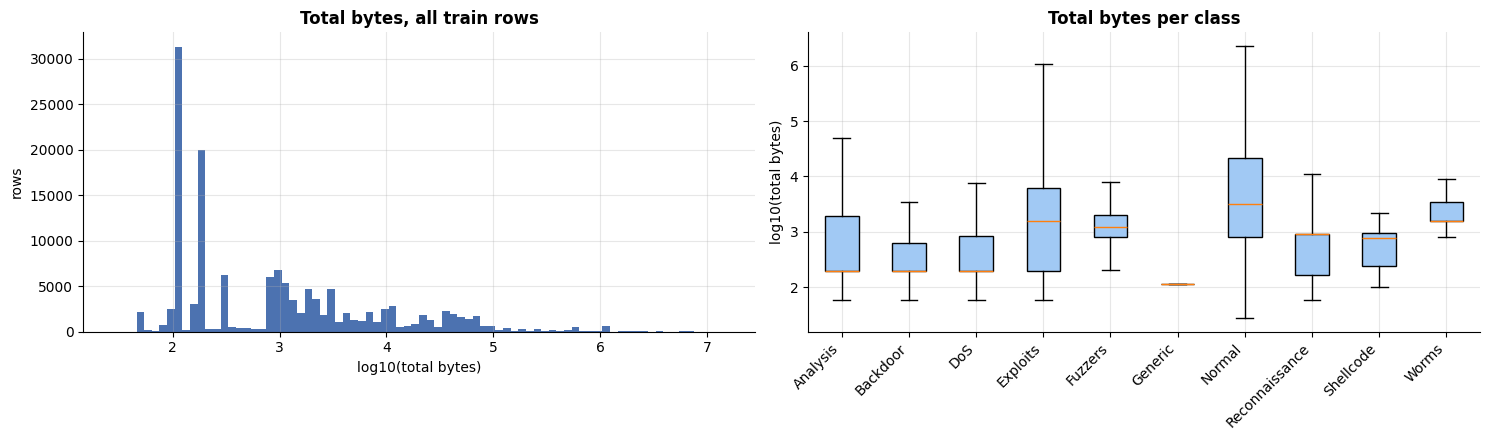

attack_cat,Analysis,Backdoor,DoS,Exploits,Fuzzers,Generic,Normal,Reconnaissance,Shellcode,Worms
median total bytes,200.0000,200.0000,200.0000,"1,592.0000","1,242.0000",114.0000,"3,184.0000",918.0000,770.0000,"1,582.0000"


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].hist(np.log10(fit.fe_total_bytes), bins=80, color='#4C72B0')
axes[0].set(title='Total bytes, all train rows', xlabel='log10(total bytes)', ylabel='rows')
data = [np.log10(fit.loc[fit.attack_cat == c, 'fe_total_bytes']) for c in CLASSES]
axes[1].boxplot(data, showfliers=False, patch_artist=True, boxprops=dict(facecolor='#A1C9F4'))
axes[1].set_xticks(range(1, 11), CLASSES, rotation=45, ha='right')
axes[1].set(title='Total bytes per class', ylabel='log10(total bytes)')
plt.tight_layout(); save_figure(fig, '04_total_bytes'); plt.show()

display(fit.groupby('attack_cat').fe_total_bytes.median().reindex(CLASSES).rename('median total bytes').to_frame().T)

**What we see:** Generic flows are tiny (median **114 bytes**) and Analysis, Backdoor and DoS flows are small too (median **200 bytes**).
Normal flows are much larger (median **3,184 bytes**) and Exploits, Fuzzers and Worms sit in between.
Total bytes separates "small, fixed-size" traffic from "real exchanges" in one number.

## 5. Feature 2: byte balance

`fe_byte_balance = (sbytes - dbytes) / (sbytes + dbytes)`. Values near **+1** mean almost no data came back.

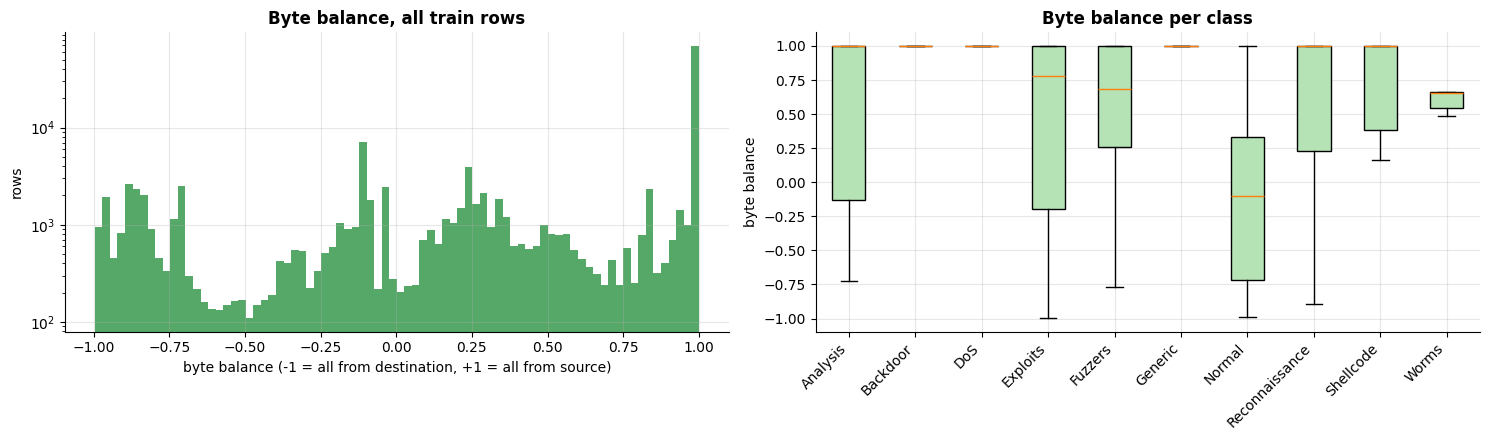

attack_cat,Analysis,Backdoor,DoS,Exploits,Fuzzers,Generic,Normal,Reconnaissance,Shellcode,Worms
% of flows with byte balance = +1 (no reply data),71.3125,80.6013,79.3191,39.3726,35.0725,98.7344,11.7277,50.5779,50.4961,10.5769


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].hist(fit.fe_byte_balance, bins=80, color='#55A868')
axes[0].set(title='Byte balance, all train rows', xlabel='byte balance (-1 = all from destination, +1 = all from source)', ylabel='rows', yscale='log')
data = [fit.loc[fit.attack_cat == c, 'fe_byte_balance'] for c in CLASSES]
axes[1].boxplot(data, showfliers=False, patch_artist=True, boxprops=dict(facecolor='#B6E3B6'))
axes[1].set_xticks(range(1, 11), CLASSES, rotation=45, ha='right')
axes[1].set(title='Byte balance per class', ylabel='byte balance')
plt.tight_layout(); save_figure(fig, '04_byte_balance'); plt.show()

one_sided = (fit.fe_byte_balance == 1).groupby(fit.attack_cat).mean().reindex(CLASSES) * 100
display(one_sided.rename('% of flows with byte balance = +1 (no reply data)').to_frame().T)

**What we see:** Most **Generic, DoS, Backdoor and Analysis** flows have a byte balance of exactly **+1**: the destination sent no data back.
Most **Normal** flows are below zero (the server's answer is bigger than the request, as in a normal download).
This is the "one-sided vs conversation" idea, now visible in a single column.

## 6. Feature 3: packet balance

`fe_packet_balance = (spkts - dpkts) / (spkts + dpkts)`. Same idea, but counting packets instead of bytes.

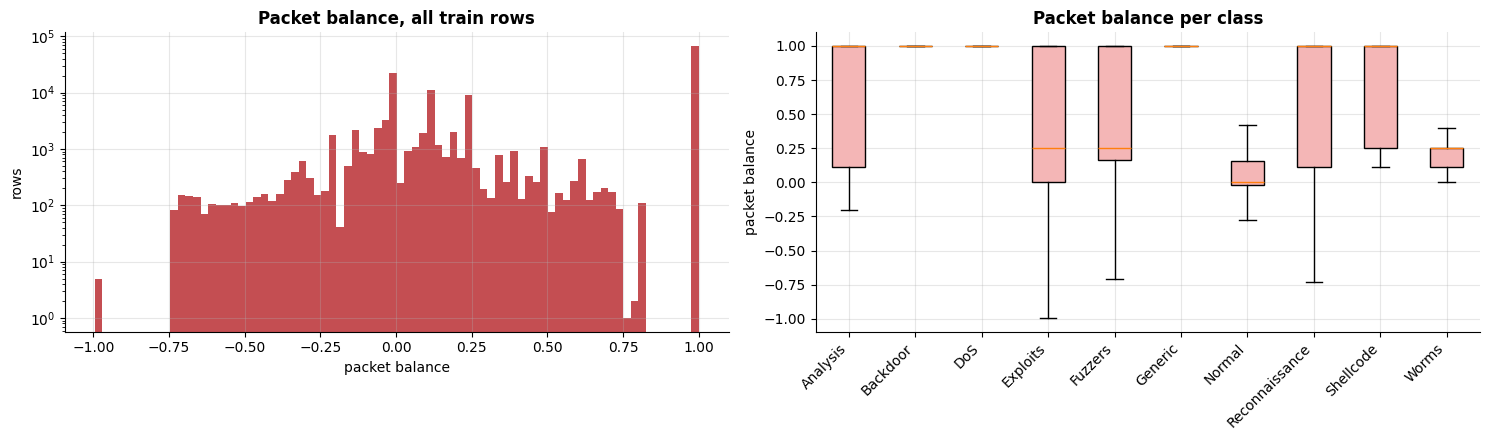

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].hist(fit.fe_packet_balance, bins=80, color='#C44E52')
axes[0].set(title='Packet balance, all train rows', xlabel='packet balance', ylabel='rows', yscale='log')
data = [fit.loc[fit.attack_cat == c, 'fe_packet_balance'] for c in CLASSES]
axes[1].boxplot(data, showfliers=False, patch_artist=True, boxprops=dict(facecolor='#F4B6B6'))
axes[1].set_xticks(range(1, 11), CLASSES, rotation=45, ha='right')
axes[1].set(title='Packet balance per class', ylabel='packet balance')
plt.tight_layout(); save_figure(fig, '04_packet_balance'); plt.show()

**What we see:** The class picture is similar to byte balance. Packets are usually more evenly split than bytes,
because acknowledgement packets flow back even when little data does.

## 7. How do the classes look with the new features together?

Each dot is a flow (a random sample of 2,000 per class, so small classes stay visible). The x-axis is the flow size and the y-axis is its direction.

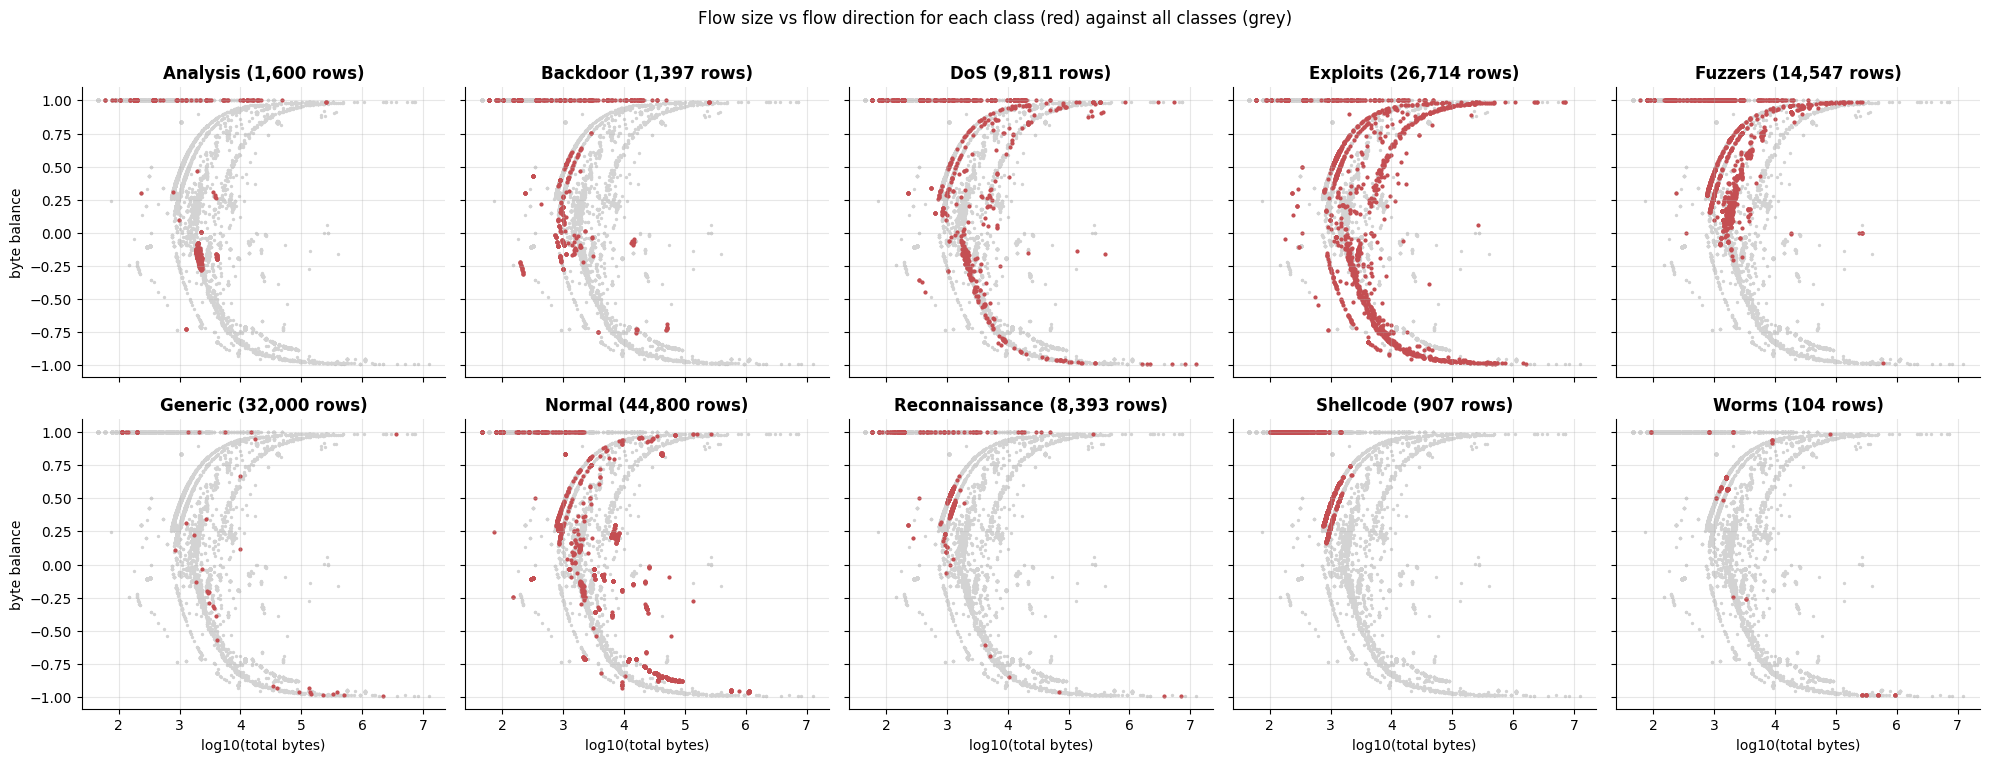

In [8]:
sample = pd.concat([g.sample(min(len(g), 2000), random_state=0) for _, g in fit.groupby('attack_cat')])
fig, axes = plt.subplots(2, 5, figsize=(20, 7.5), sharex=True, sharey=True)
for ax, cls in zip(axes.ravel(), CLASSES):
    ax.scatter(np.log10(sample.fe_total_bytes), sample.fe_byte_balance, s=2, color='lightgrey')
    part = sample[sample.attack_cat == cls]
    ax.scatter(np.log10(part.fe_total_bytes), part.fe_byte_balance, s=4, color='#C44E52')
    ax.set_title(f'{cls} ({len(fit[fit.attack_cat == cls]):,} rows)')
for ax in axes[1]:
    ax.set_xlabel('log10(total bytes)')
for ax in axes[:, 0]:
    ax.set_ylabel('byte balance')
fig.suptitle('Flow size vs flow direction for each class (red) against all classes (grey)', y=1.01)
plt.tight_layout(); save_figure(fig, '04_size_vs_direction'); plt.show()

**What we see:**

- **Generic** sits almost entirely in the top-left corner: tiny flows with no reply (+1).
- **Normal** is spread widely over many sizes and directions; it is the most varied class.
- **Analysis and Backdoor** sit in the same two small spots (one-sided small flows, and flows of about 2,000 bytes with balance slightly below 0).
- **DoS and Exploits** lie on the same curved bands. These bands come from flows with similar request sizes and growing replies.

The new features describe the traffic in an understandable way. They cannot separate classes that the original measurements
already could not separate (Analysis / Backdoor / DoS / Exploits).

## 8. Do the new features add anything new?

The new columns are calculated from existing ones, so they contain **no new measurements**. The real question is whether they express
the information in a more useful way. We check how strongly each new feature is related to the existing columns (Spearman correlation).

In [9]:
numeric = [c for c in raw.columns if c not in TARGETS + CATEGORICAL + ['role']]
corr = fit[NEW + numeric].corr(method='spearman').loc[NEW, numeric]
closest = pd.DataFrame({'most similar existing column': corr.abs().idxmax(axis=1),
                        'spearman with it': [corr.loc[f, corr.abs().idxmax(axis=1)[f]] for f in NEW]})
closest['spearman between the two balances'] = [np.nan, fit.fe_byte_balance.corr(fit.fe_packet_balance, method='spearman'), np.nan]
save_table(closest, '04_similarity_to_existing', index=True)
display(closest)

,most similar existing column,spearman with it,spearman between the two balances
fe_total_bytes,sbytes,0.9647,NaN
fe_byte_balance,dmean,-0.9753,0.9734
fe_packet_balance,dmean,-0.9594,NaN


**What we see:**

- `fe_total_bytes` is strongly related to `sbytes` (0.96): most bytes come from the source. It is not identical, because it also includes the reply.
- `fe_byte_balance` follows `dmean` (average reply packet size) very closely in ranking (-0.98). The reason is the many flows with **no reply**:
  for them `dbytes = 0`, so `dmean = 0` and the balance is exactly +1. Both columns are mainly saying "did anything come back, and how much?".
- The two balances are **very similar to each other** (0.97).

**Honest conclusion:** the new features are mostly **re-expressions** of information the data already contains. Their value is that they
put "size" and "direction" into single, bounded, easy-to-read numbers. Whether that helps a model is a question for the models (Notebook 06),
and whether we need both balances is a question for Notebook 05.

## 9. Ideas we considered and did not keep

We also tried three other common flow features. They turned out to be almost copies of columns we already have:

In [10]:
candidates = pd.DataFrame({
    'packets per second = (spkts + dpkts) / dur': safe_divide(fit.spkts + fit.dpkts, fit.dur),
    'source bytes per packet = sbytes / spkts': safe_divide(fit.sbytes, fit.spkts),
    'destination bytes per packet = dbytes / dpkts': safe_divide(fit.dbytes, fit.dpkts),
}, index=fit.index)
existing = {'packets per second = (spkts + dpkts) / dur': 'rate',
            'source bytes per packet = sbytes / spkts': 'smean',
            'destination bytes per packet = dbytes / dpkts': 'dmean'}
rejected = pd.DataFrame([{'idea': k, 'existing column': v,
                          'spearman': candidates[k].corr(fit[v], method='spearman'),
                          'decision': f'not kept: already measured by {v}'} for k, v in existing.items()])
save_table(rejected, '04_rejected_ideas')
display(rejected)

,idea,existing column,spearman,decision
0,packets per second = (spkts + dpkts) / dur,rate,0.9969,not kept: already measured by rate
1,source bytes per packet = sbytes / spkts,smean,0.9993,not kept: already measured by smean
2,destination bytes per packet = dbytes / dpkts,dmean,0.9999,not kept: already measured by dmean


**What we see:** each idea correlates almost perfectly with an existing column (`rate`, `smean`, `dmean`). Adding them would only repeat information,
so we keep just the three features that express something new.

## 10. Add the features to all three roles

The formulas have no learned parts, so they are simply applied to every role. For the model inputs:

- **Tree version:** the three raw values are appended as three extra columns.
- **Scaled version:** total bytes gets `log(1 + x)` then robust scaling (it is skewed like the other byte columns); the two balances
  are already between -1 and +1 and only get robust scaling. This small scaler is **fitted on the train role only**.

In [11]:
engineered = {role: add_flow_features(raw[raw.role == role]) for role in ROLES}

scaler = ColumnTransformer([
    ('volume', Pipeline([('log', FunctionTransformer(np.log1p, feature_names_out='one-to-one')), ('scale', RobustScaler())]), ['fe_total_bytes']),
    ('balance', RobustScaler(), ['fe_byte_balance', 'fe_packet_balance']),
], verbose_feature_names_out=False)
scaler.fit(engineered['train'])

inputs = {}
for role in ROLES:
    tree = sparse.load_npz(DATA / f'03_tree_{role}.npz')
    scaled = sparse.load_npz(DATA / f'03_scaled_{role}.npz')
    inputs[('tree', role)] = sparse.hstack([tree, sparse.csr_matrix(engineered[role][NEW].to_numpy())], format='csr')
    inputs[('scaled', role)] = sparse.hstack([scaled, sparse.csr_matrix(scaler.transform(engineered[role][NEW]))], format='csr')

display(pd.DataFrame({role: [inputs[('tree', role)].shape, inputs[('scaled', role)].shape] for role in ROLES},
                     index=['tree version + 3', 'scaled version + 3']))

,train,model_selection,calibration
tree version + 3,"(140273, 196)","(17534, 196)","(17534, 196)"
scaled version + 3,"(140273, 196)","(17534, 196)","(17534, 196)"


### Checks

1. Rows stay in the same order and every value is finite.
2. The new values match the engineered columns saved by the earlier project version, so all results stay comparable.
3. Adding columns cannot make two different rows identical, so the "no shared patterns between roles" rule from Notebook 02 still holds.

In [12]:
check = []
for role in ROLES:
    previous = pd.read_csv(ROOT / f'data/processed/04/04_engineered_{role}.csv')
    old_tree = sparse.load_npz(ROOT / f'data/processed/04/04_tree_augmented_{role}.npz')
    old_scaled = sparse.load_npz(ROOT / f'data/processed/04/04_scaled_augmented_{role}.npz')
    check.append({'role': role, 'rows': len(engineered[role]),
                  'all finite': bool(np.isfinite(engineered[role].to_numpy()).all()),
                  'same values as earlier version': bool(np.allclose(previous[NEW].to_numpy(), engineered[role][NEW].to_numpy(), rtol=0, atol=1e-12)),
                  'tree input identical': bool(abs(old_tree - inputs[('tree', role)]).max() < 1e-12),
                  'scaled input identical': bool(abs(old_scaled - inputs[('scaled', role)]).max() < 1e-9)})
check = pd.DataFrame(check)
save_table(check, '04_checks')
display(check)
assert check.drop(columns=['role', 'rows']).all().all()

,role,rows,all finite,same values as earlier version,tree input identical,scaled input identical
0,train,140273,True,True,True,True
1,model_selection,17534,True,True,True,True
2,calibration,17534,True,True,True,True


## 11. Save

In [13]:
for role in ROLES:
    out = engineered[role].copy()
    out.insert(0, 'row_position', np.flatnonzero(raw.role == role))
    out.to_csv(DATA / f'04_engineered_{role}.csv', index=False)
    sparse.save_npz(DATA / f'04_tree_plus3_{role}.npz', inputs[('tree', role)])
    sparse.save_npz(DATA / f'04_scaled_plus3_{role}.npz', inputs[('scaled', role)])
joblib.dump(scaler, MODELS / '04_engineered_scaler.joblib')
names = read_json(MODELS / '03_feature_names.json')
save_json({'tree': names['tree'] + NEW, 'scaled': names['scaled'] + NEW,
           'formulas': {'fe_total_bytes': 'sbytes + dbytes',
                        'fe_byte_balance': '(sbytes - dbytes) / (sbytes + dbytes), 0 if total is 0',
                        'fe_packet_balance': '(spkts - dpkts) / (spkts + dpkts), 0 if total is 0'}},
          MODELS / '04_feature_names.json')
assert sha256(TRAIN_CSV) == RAW_SHA256['train']
print('Saved engineered columns and model inputs for all roles. Raw file unchanged.')

Saved engineered columns and model inputs for all roles. Raw file unchanged.


## Summary

### What we did

We created **three new features** from the byte and packet counts:

| Feature | Meaning | Main observation |
|---|---|---|
| `fe_total_bytes` | total size of the flow | Generic flows are tiny and uniform; Normal flows are large and varied |
| `fe_byte_balance` | direction of the bytes | Most Generic, DoS, Backdoor and Analysis flows are fully one-sided (+1) |
| `fe_packet_balance` | direction of the packets | Similar story to byte balance, very strongly related to it (0.97) |

We rejected packets-per-second and bytes-per-packet because `rate`, `smean` and `dmean` already measure them.
All 42 original columns stay; the model inputs now have 42 + 3 = **45 features**.

### What is still uncertain

- The new features are **re-expressions** of existing counts, not new measurements. Whether they help a model is not proven yet.
- The two balances may be redundant with each other.

### What Notebook 05 does next

**Feature selection:** check all 45 features for copies, near-copies and usefulness, decide which ones to carry forward
(including whether both balances are needed), and prepare the final inputs for the baseline models.